# Plotting Functionality

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("SPECT/Lu177-PSMA-GEDisc")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("SPECT/Lu177-PSMA-GEDisc")

SPECT/Lu177-PSMA-GEDisc: already downloaded


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from pytomography import io
from pytomography.utils import plot_utils

Paths are set in the data cell at the top of this tutorial.

In [3]:
save_path = DATA / 'SPECT'

We'll start by opening up a CT image, and a reconstructed SPECT image from the DICOM multibed tutorial:

In [4]:
path_CT = os.path.join(save_path, 'Lu177-PSMA-GEDisc', 'CT')
files_CT = [os.path.join(path_CT, file) for file in os.listdir(path_CT)]
path_SPECT = os.path.join(save_path, 'Lu177-PSMA-GEDisc', 'pytomo_recon')
file_SPECT = os.path.join(path_SPECT, os.listdir(path_SPECT)[0])

To plot images on top of eachother, we need both the images and their affine matrices (voxel index to position in the patient, LPS mm). `io.load_image` reads each file into an `Image`, which holds both: `.data` and `.affine`.

In [5]:
spect = io.load_image(file_SPECT)
ct = io.load_image(files_CT)
print(spect)
print(ct)

Image(shape=(128, 128, 208), voxel_size=(4.4196, 4.4196, 4.4196), centre=(0.3, -6.9, 0.216), units=None, modality='NM', frame='patient')
Image(shape=(512, 512, 303), voxel_size=(0.9766, 0.9766, 2.5), centre=(-0.0, -0.0, -0.5), units='HU', modality='CT', frame='patient')


Now we provide dictionaries of arguments for the `matplotlib.pyplot.imshow` function for each of the two images:

In [6]:
SPECT_imshow_kwargs = {
    'cmap': plot_utils.pet_cmap,
    'interpolation': 'Gaussian',
    'alpha': 0.6,
    'vmin': 0,
    'vmax': 350,
    'zorder': 1, # this will ensure SPECT is on top of CT
    'origin': 'lower'
}
CT_imshow_kwargs = {
    'cmap': 'Greys_r',
    'interpolation': 'Gaussian',
    'vmin': -150, # HU
    'vmax': 475, # HU
    'zorder': 0,
    'origin': 'lower'
}

We can then plot the 3 slices as follows:

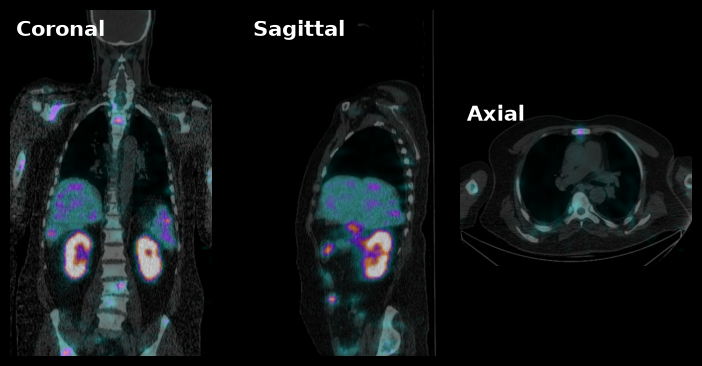

In [7]:
fig, ax = plt.subplots(1,3,figsize=(9,4.5), gridspec_kw={'wspace':0.0}, facecolor='k')
plt.sca(ax[0])
plot_utils.dual_imshow_coronal(
    im1 = spect.data,
    im2 = ct.data,
    im1_idx = 80,
    affine1 = spect.affine,
    affine2 = ct.affine,
    imshow1_kwargs=SPECT_imshow_kwargs,
    imshow2_kwargs=CT_imshow_kwargs,
)
plt.xlim(-200,220)
plt.ylim(-350,370)
plt.axis('off')
plt.text(0.03, 0.97, 'Coronal', color='white', fontsize=15, fontweight='bold', transform=plt.gca().transAxes, ha='left', va='top')

plt.sca(ax[1])
plot_utils.dual_imshow_sagittal(
    im1 = spect.data,
    im2 = ct.data,
    im1_idx = 50,
    affine1 = spect.affine,
    affine2 = ct.affine,
    imshow1_kwargs=SPECT_imshow_kwargs,
    imshow2_kwargs=CT_imshow_kwargs,
)
plt.xlim(-200,200)
plt.ylim(-350,370)
plt.axis('off')
plt.text(0.03, 0.97, 'Sagittal', color='white', fontsize=15, fontweight='bold', transform=plt.gca().transAxes, ha='left', va='top')

plt.sca(ax[2])
plot_utils.dual_imshow_axial(
    im1 = spect.data,
    im2 = ct.data,
    im1_idx = 117,
    affine1 = spect.affine,
    affine2 = ct.affine,
    imshow1_kwargs=SPECT_imshow_kwargs,
    imshow2_kwargs=CT_imshow_kwargs,
)
plt.xlim(-200,220)
plt.ylim(200,-100)
plt.axis('off')
plt.text(0.03, 0.97, 'Axial', color='white', fontsize=15, fontweight='bold', transform=plt.gca().transAxes, ha='left', va='top')
plt.show()

Often, I like using a further customized PET cmap that changes with transparency for lower value. We can do this by modiying the PET colormap. I've found that this function tends to work well:

In [8]:
def cmap_f(x,a):
    return (1-np.exp(-x/a))/(1+np.exp(-x/a))
x = np.linspace(0,1,256)
colors = plot_utils.pet_cmap(x)
colors[:, -1] = 0.8*cmap_f(x, a=3e-2) # this value works well
new_pet_cmap = mcolors.LinearSegmentedColormap.from_list('NewColormap', colors)

In [9]:
SPECT_imshow_kwargs = {
    'cmap': new_pet_cmap,
    'interpolation': 'Gaussian',
    'alpha': 0.8, # Change the alpha higher now for more visibilty
    'vmin': 0,
    'vmax': 350,
    'zorder': 1,
    'origin': 'lower'
}
CT_imshow_kwargs = {
    'cmap': 'Greys_r',
    'interpolation': 'Gaussian',
    'vmin': -150, # HU
    'vmax': 475, # HU
    'zorder': 0,
    'origin': 'lower'
}

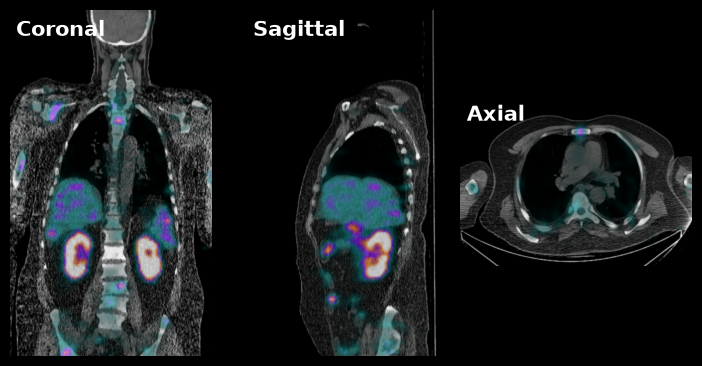

In [10]:
fig, ax = plt.subplots(1,3,figsize=(9,4.5), gridspec_kw={'wspace':0.0}, facecolor='k')
plt.sca(ax[0])
plot_utils.dual_imshow_coronal(
    im1 = spect.data,
    im2 = ct.data,
    im1_idx = 80,
    affine1 = spect.affine,
    affine2 = ct.affine,
    imshow1_kwargs=SPECT_imshow_kwargs,
    imshow2_kwargs=CT_imshow_kwargs,
)
plt.xlim(-200,220)
plt.ylim(-350,370)
plt.axis('off')
plt.text(0.03, 0.97, 'Coronal', color='white', fontsize=15, fontweight='bold', transform=plt.gca().transAxes, ha='left', va='top')

plt.sca(ax[1])
plot_utils.dual_imshow_sagittal(
    im1 = spect.data,
    im2 = ct.data,
    im1_idx = 50,
    affine1 = spect.affine,
    affine2 = ct.affine,
    imshow1_kwargs=SPECT_imshow_kwargs,
    imshow2_kwargs=CT_imshow_kwargs,
)
plt.xlim(-200,200)
plt.ylim(-350,370)
plt.axis('off')
plt.text(0.03, 0.97, 'Sagittal', color='white', fontsize=15, fontweight='bold', transform=plt.gca().transAxes, ha='left', va='top')

plt.sca(ax[2])
plot_utils.dual_imshow_axial(
    im1 = spect.data,
    im2 = ct.data,
    im1_idx = 117,
    affine1 = spect.affine,
    affine2 = ct.affine,
    imshow1_kwargs=SPECT_imshow_kwargs,
    imshow2_kwargs=CT_imshow_kwargs,
)
plt.xlim(-200,220)
plt.ylim(200,-100)
plt.axis('off')
plt.text(0.03, 0.97, 'Axial', color='white', fontsize=15, fontweight='bold', transform=plt.gca().transAxes, ha='left', va='top')
plt.show()

## Save the images

`io.save_dicom` also saves an `Image`, which carries its own affine and modality: here the SPECT image, as a DICOM nuclear medicine (NM) file, with the patient, study and frame of reference of the file it came from (`reference=file_SPECT`).

In [11]:
saved = io.save_dicom(spect, OUTPUT / 't_plotting' / 'spect', reference=file_SPECT,
                      series_description='Stitched OSEM', overwrite=True)

In [12]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 0.0, "peak_ram_gb": 3.4}
